In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

df_amazon=pd.read_csv('C:/Users/ULI/ProjectsJupiter/data/amz_uk_price_prediction_dataset.csv')

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?


1. **Frequency Tables**:

In [28]:
df_amazon.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [6]:
freq_table=df_amazon['category'].value_counts()
freq_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [7]:
freq_table=df_amazon['category'].value_counts()[:5]
freq_table

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. **Visualizations**:

([], [])

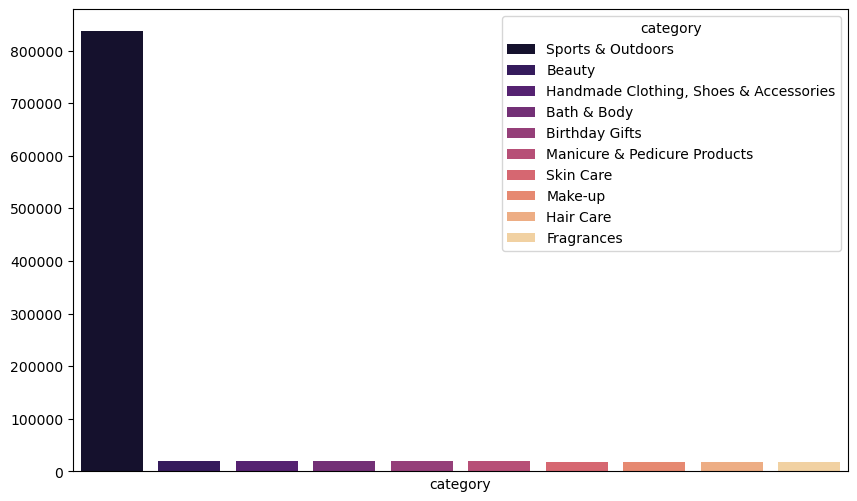

In [8]:
top10_cat=df_amazon['category'].value_counts()[:10]

plt.figure(figsize=(10, 6))
sns.barplot(x=top10_cat.index,
    y=top10_cat.values,
    hue=top10_cat.index,
    palette='magma',
    legend=True)
plt.xticks([])

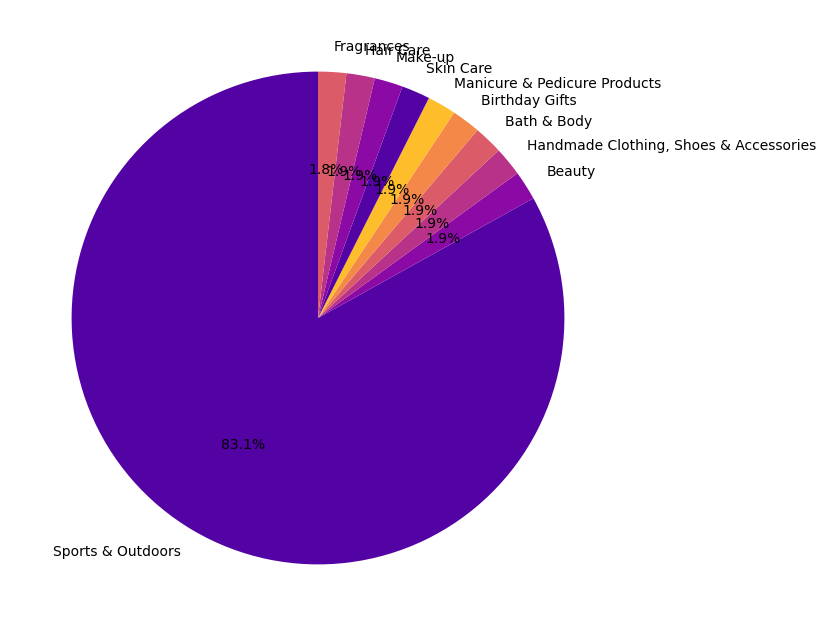

In [16]:
plt.figure(figsize=(10, 8))
plt.pie(
    x=top10_cat.values,           
    labels=top10_cat.index,       
    autopct='%1.1f%%',            
    startangle=90,
    colors=sns.color_palette('plasma'),)
plt.show()

Sports & Outdoors category dominate the listings!

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


1. **Measures of Centrality**:

In [21]:
print(f"""
Mean:   {df_amazon['price'].mean()}
Median: {df_amazon['price'].median()}
Mode:   {df_amazon['price'].mode()[0]}
""")


Mean:   89.24380943923661
Median: 19.09
Mode:   9.99



The average price of products is the Mean: 89.24$ and the most common price is the Mode: 9.99$.
That means the dataset is has an extremetly dispersion.

2. **Measures of Dispersion**:

In [25]:
print(f"""
Variance:           {df_amazon['price'].var():.2f}
Standard Deviation: {df_amazon['price'].std():.2f}
Range:              {df_amazon['price'].max() - df_amazon['price'].min()}
IQR:                {df_amazon['price'].quantile(0.75) - df_amazon['price'].quantile(0.25)}
""")


Variance:           119445.49
Standard Deviation: 345.61
Range:              100000.0
IQR:                36.0



How varied are the product prices? Are there any indicators of a significant spread in prices?

The high difference between Mean and Median means that Dataset has high dispersion and outliers, Range 100000 is another indicator of a significant spread.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


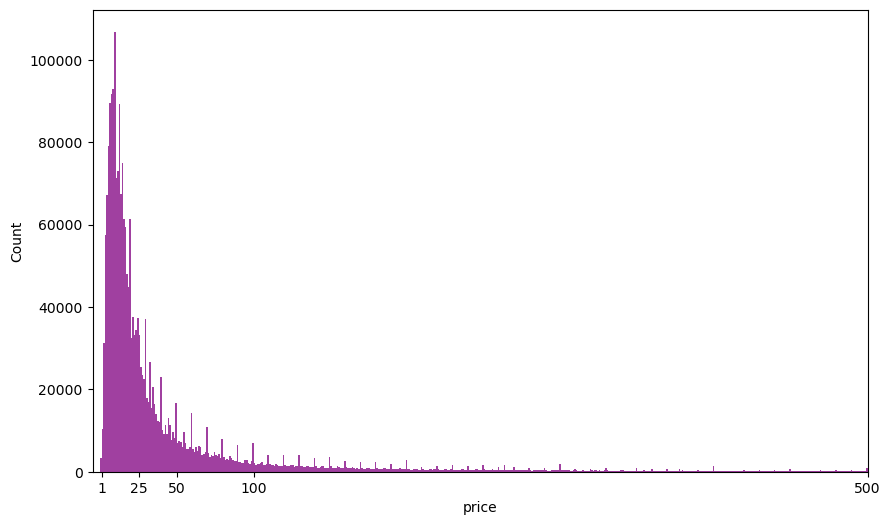

In [50]:
plt.figure(figsize=(10, 6))
sns.histplot(df_amazon['price'], color='purple',binwidth=1)
plt.xticks([1, 25, 50, 100, 500, 1000])
plt.xlim(-5, 500)
plt.show()

The highest price is 9.99 Mode, and starts falling from there til 25 and goes to 0.

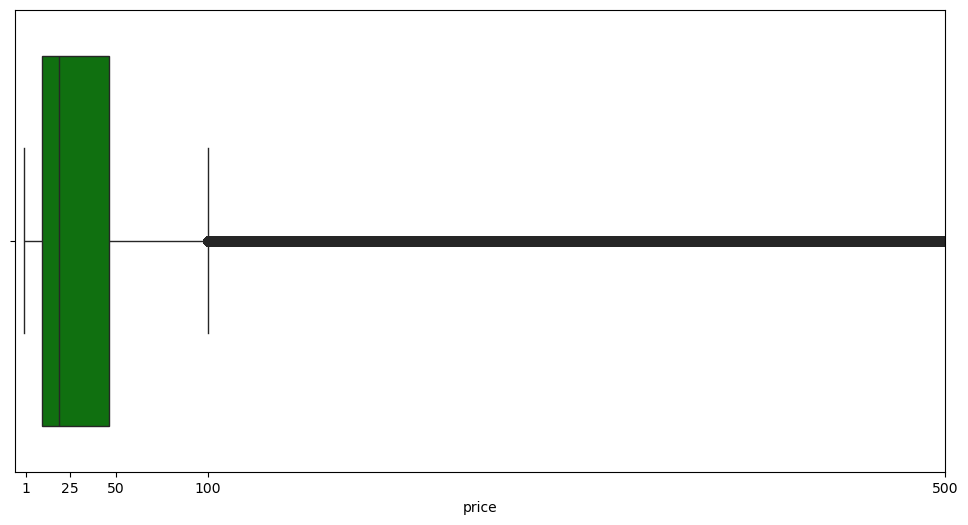

In [51]:
plt.figure(figsize=(12, 6))
sns.boxplot(x=df_amazon['price'], color='green')
plt.xticks([1, 25, 50, 100, 500, 1000])
plt.xlim(-5, 500)
plt.show()

The Boxplot show us that there are a lot of outliers in the dataset. 50% of the values are between 10 and 46 (Green Box) and the median is 19$.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

1. **Measures of Centrality**:

In [32]:
freq_rev = df_amazon['reviews'].value_counts()
freq_rev

reviews
0         1225641
1           90033
2           54452
3           39922
4           30720
           ...   
13246           1
16044           1
25872           1
8503            1
547940          1
Name: count, Length: 19446, dtype: int64

In [30]:
freq_stars = df_amazon['stars'].value_counts()
freq_stars

stars
0.0    1225641
4.5     151577
4.6     136995
4.4     136165
5.0     128492
4.3     112564
4.7      94566
4.2      86871
4.0      66089
4.1      65115
4.8      41858
3.9      36555
3.8      27876
3.7      21137
3.6      16219
3.5      14673
3.0      12819
4.9      11081
3.4      10355
1.0       8484
3.3       8269
3.2       5771
3.1       4679
2.0       3901
2.9       3341
2.8       2306
2.7       2104
2.5       2103
2.6       1579
2.4       1060
2.3        734
2.2        602
2.1        540
1.5        404
1.9        300
1.8        249
1.7        177
1.4        149
1.6        147
1.3         78
1.2         23
1.1          3
Name: count, dtype: int64

In [29]:
print(f"""
RATING:
Mean:   {df_amazon['stars'].mean()}
Median: {df_amazon['stars'].median()}
Mode:   {df_amazon['stars'].mode()[0]}
""")


RATING:
Mean:   2.152836472966066
Median: 0.0
Mode:   0.0



Buyers use to not rate or rate with 0 Stars

2. **Measures of Dispersion**:

In [33]:
print(f"""
STARS:
Variance:           {df_amazon['stars'].var():.2f}
Standard Deviation: {df_amazon['stars'].std():.2f}
Range:              {df_amazon['stars'].max() - df_amazon['stars'].min()}
IQR:                {df_amazon['stars'].quantile(0.75) - df_amazon['stars'].quantile(0.25)}
""")


STARS:
Variance:           4.82
Standard Deviation: 2.19
Range:              5.0
IQR:                4.4



Results are not consistent. IQR is 4.4 means and that 50% of the stars are almost the range 5.0.
Mode and median are 0, so the dataset is skewed to zero.


3. **Shape of the Distribution**:
 
Calculate the skewness and kurtosis for the rating column.

Are the ratings normally distributed, or do they lean towards higher or lower values?


In [53]:
print(f"""
Skewness: {df_amazon['stars'].skew()}
Kurtosis: {df_amazon['stars'].kurt()}
""")


Skewness: 0.08120735761080881
Kurtosis: -1.9260061280432994



In [ ]:
The ratings are not normally distributed, they lean towards lower values because of a massive ratings with 0 stars (No rate or bad reviews).
The skewness is 0.08, so close to 0, so is simetric because of the mount of rating between 3 and 5.


4. **Visualizations**:

Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

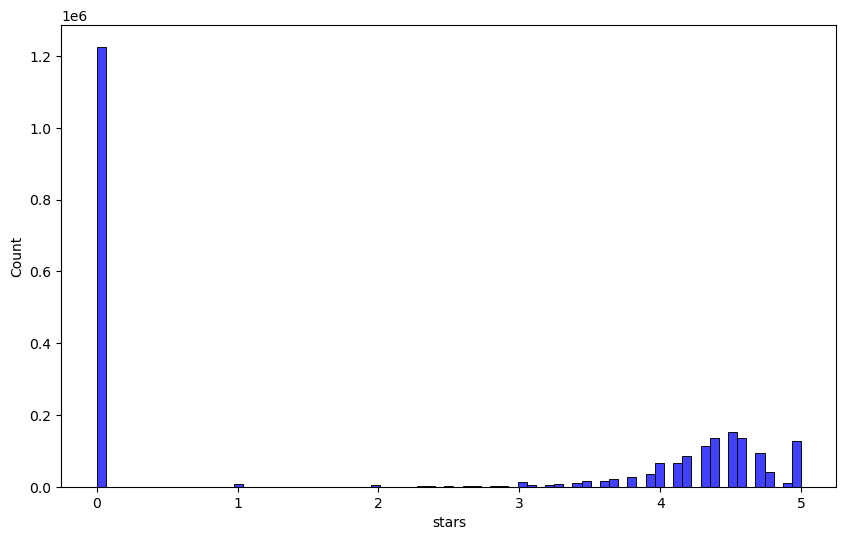

In [56]:
plt.figure(figsize=(10, 6))
sns.histplot(df_amazon['stars'], color='blue')
plt.show()